# 02 — Exploratory Data Analysis

Notebook này phân tích bộ dữ liệu khách hàng sau làm sạch và sau khi tạo biến mục tiêu `Purchase_Level`. Mục tiêu là mô tả dữ liệu, so sánh ba nhóm khách hàng và rà soát nguy cơ data leakage trước khi xây dựng mô hình phân loại.

Quy ước target đã được cố định: `Low ≤ 10`, `10 < Medium ≤ 15`, `High > 15`. `Total_Purchases` được giữ nguyên, không làm tròn.

## 1. Load Data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
plt.style.use("seaborn-v0_8-whitegrid")

current_dir = Path.cwd().resolve()
BASE_DIR = current_dir if (current_dir / "data").exists() else current_dir.parent
DATA_PATH = BASE_DIR / "data" / "processed" / "ecommerce_customer_behavior_with_target.csv"
OUTPUT_DIR = BASE_DIR / "reports" / "figures" / "eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy dataset: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
level_order = ["Low", "Medium", "High"]
df["Purchase_Level"] = pd.Categorical(
    df["Purchase_Level"], categories=level_order, ordered=True
)

required_columns = {"Total_Purchases", "Purchase_Level", "Churned"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")

print(f"Dataset: {DATA_PATH}")
print(f"Số dòng: {len(df):,}")
print(f"Số cột: {df.shape[1]}")
print(f"Tổng missing values: {df.isna().sum().sum():,}")
df.head()

Dataset: data\processed\ecommerce_customer_behavior_with_target.csv
Số dòng: 49,960
Số cột: 26
Tổng missing values: 0


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Purchase_Level
0,43.00,Male,France,Marseille,2.90,14.00,27.40,6.00,50.60,3.00,9.00,94.72,34.00,46.40,2.00,17.90,9.00,4.00,16.30,20.80,1.00,953.33,"2,278.00",0,Q1,Low
1,36.00,Male,UK,Manchester,1.60,15.00,42.70,10.30,37.70,1.00,19.50,82.45,71.00,57.96,9.20,42.80,7.00,3.00,27.60,23.30,3.00,"1,067.47","3,028.00",0,Q4,High
2,45.00,Female,Canada,Vancouver,2.90,10.00,24.80,1.60,70.90,1.00,9.10,165.52,11.00,12.24,11.50,0.00,4.00,1.00,27.60,8.80,2.00,"1,289.75","2,317.00",0,Q4,Low
3,56.00,Female,USA,New York,2.60,10.00,38.40,14.80,41.70,9.00,15.00,147.33,47.00,44.10,5.40,41.40,2.00,5.00,85.90,31.00,3.00,"2,340.92","2,674.00",0,Q1,Medium
4,35.00,Male,India,Delhi,3.10,29.00,51.40,8.40,19.10,9.00,32.50,141.30,73.00,25.20,5.50,37.90,1.00,11.00,83.00,50.40,4.00,"3,041.29","5,354.00",0,Q4,High


## 2. Target Analysis

Phân tích phân bố `Purchase_Level`, phạm vi `Total_Purchases` và một số đặc trưng hành vi theo từng nhóm.

In [2]:
target_counts = df["Purchase_Level"].value_counts(sort=False).reindex(level_order)
target_percentages = target_counts.div(len(df)).mul(100)
target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages,
})
target_distribution

,Count,Percentage
Purchase_Level,,
Low,18953,37.94
Medium,15130,30.28
High,15877,31.78


In [3]:
purchase_summary = (
    df.groupby("Purchase_Level", observed=False)["Total_Purchases"]
    .agg(["count", "min", "max", "mean", "median", "std"])
    .reindex(level_order)
)
purchase_summary

,count,min,max,mean,median,std
Purchase_Level,,,,,,
Low,18953,0.00,10.00,7.04,7.00,2.22
Medium,15130,10.40,15.00,12.74,13.00,1.43
High,15877,15.60,128.70,20.76,19.00,6.61


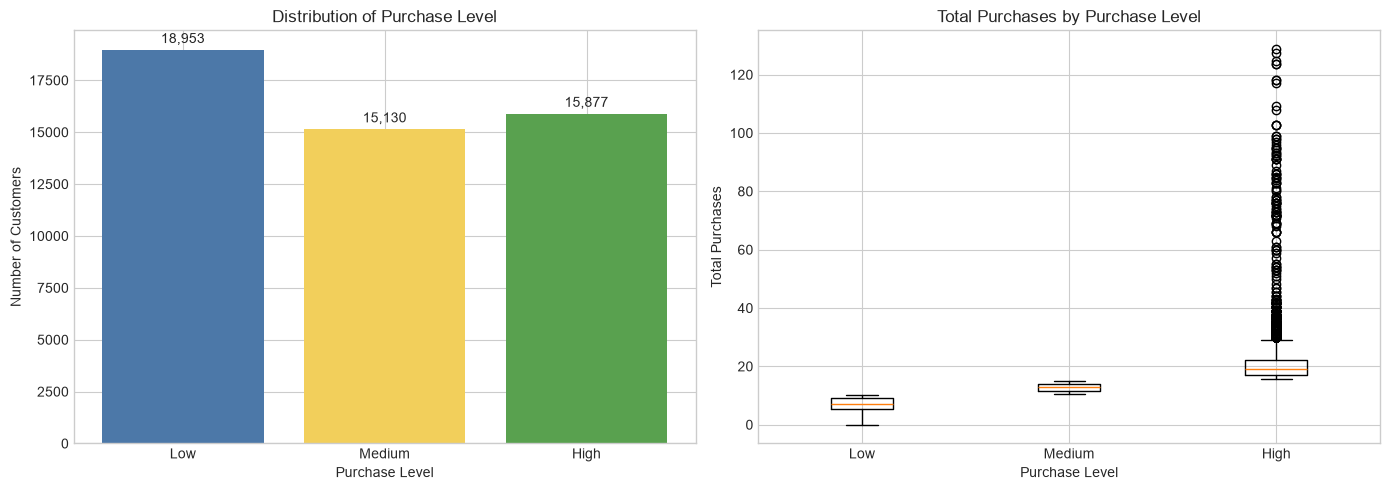

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(target_counts.index, target_counts.values, color=["#4C78A8", "#F2CF5B", "#59A14F"])
axes[0].set_title("Distribution of Purchase Level")
axes[0].set_xlabel("Purchase Level")
axes[0].set_ylabel("Number of Customers")
axes[0].bar_label(bars, labels=[f"{value:,}" for value in target_counts.values], padding=3)

plot_data = [df.loc[df["Purchase_Level"] == level, "Total_Purchases"] for level in level_order]
axes[1].boxplot(plot_data, tick_labels=level_order, showfliers=True)
axes[1].set_title("Total Purchases by Purchase Level")
axes[1].set_xlabel("Purchase Level")
axes[1].set_ylabel("Total Purchases")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "target_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

**Nhận xét:** Ba lớp tương đối cân bằng, không có lớp thiểu số nghiêm trọng. Nhóm `High` chứa một số giá trị `Total_Purchases` lớn nhưng các giá trị này không bị loại chỉ dựa trên tiêu chí IQR.

## 3. Numeric Analysis

Phần này kiểm tra thống kê mô tả, tỷ lệ giá trị bằng 0, số lượng giá trị duy nhất, độ lệch phân phối và outlier theo IQR.

In [5]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_summary = df[numeric_columns].describe().T
numeric_summary["missing"] = df[numeric_columns].isna().sum()
numeric_summary["zero_count"] = df[numeric_columns].eq(0).sum()
numeric_summary["zero_percent"] = numeric_summary["zero_count"].div(len(df)).mul(100)
numeric_summary["unique_count"] = df[numeric_columns].nunique()
numeric_summary["skewness"] = df[numeric_columns].skew()
numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv", encoding="utf-8-sig")
numeric_summary

,count,mean,std,min,25%,50%,75%,max,missing,zero_count,zero_percent,unique_count,skewness
Age,"49,960.00",37.78,11.16,18.00,30.00,38.00,45.00,75.00,0,0,0.00,58,0.23
Membership_Years,"49,960.00",2.98,2.06,0.10,1.40,2.50,4.00,10.00,0,0,0.00,200,1.14
Login_Frequency,"49,960.00",11.62,7.81,0.00,6.00,11.00,17.00,46.00,0,4026,8.06,46,0.51
Session_Duration_Avg,"49,960.00",27.60,10.50,1.00,20.20,26.80,34.00,75.60,0,0,0.00,658,0.43
Pages_Per_Session,"49,960.00",8.72,3.66,1.00,6.20,8.40,11.00,24.10,0,0,0.00,224,0.42
Cart_Abandonment_Rate,"49,960.00",57.05,16.21,0.00,46.48,58.10,68.70,100.00,0,18,0.04,970,-0.30
Wishlist_Items,"49,960.00",4.27,3.06,0.00,2.00,4.00,6.00,28.00,0,3671,7.35,25,1.01
Total_Purchases,"49,960.00",13.13,7.00,0.00,8.00,12.00,17.00,128.70,0,9,0.02,133,2.73
Average_Order_Value,"49,960.00",123.11,175.63,26.38,87.05,112.96,144.44,"9,666.38",0,0,0.00,16403,42.35
Days_Since_Last_Purchase,"49,960.00",29.27,28.87,0.00,9.00,21.00,39.00,287.00,0,813,1.63,235,2.09


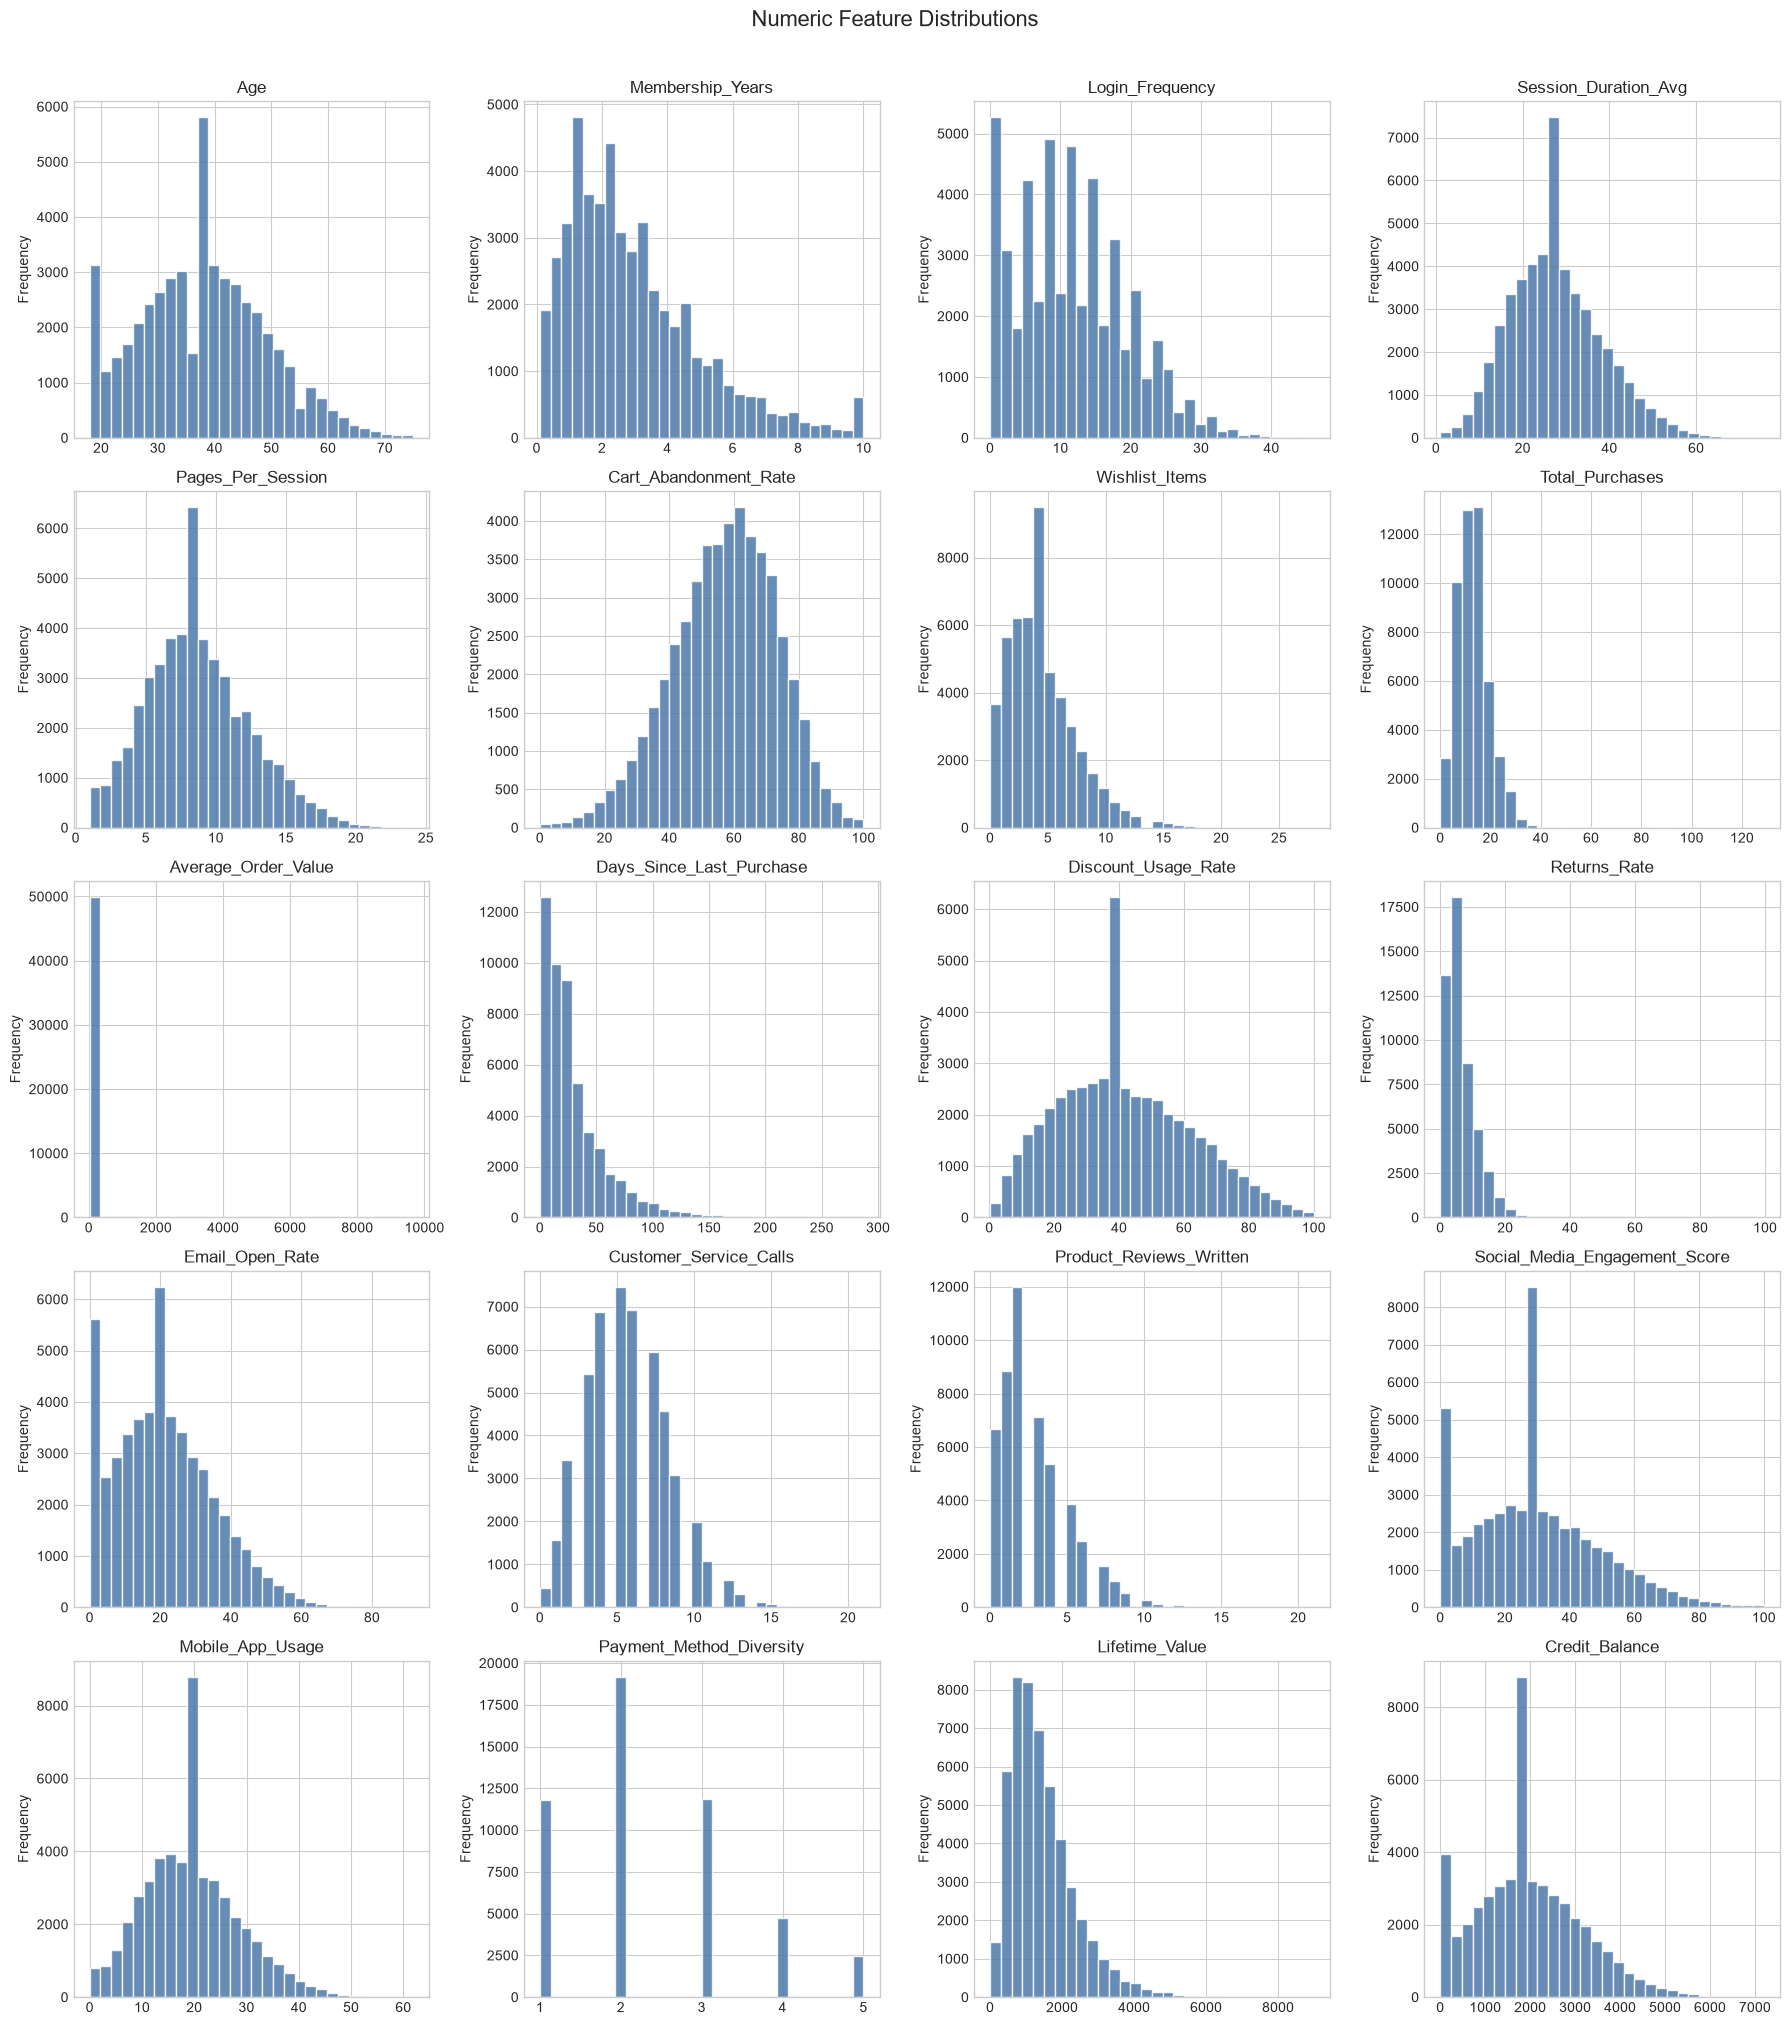

In [6]:
plot_numeric_columns = [column for column in numeric_columns if column != "Churned"]
ncols = 4
nrows = int(np.ceil(len(plot_numeric_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes = np.asarray(axes).ravel()

for axis, column in zip(axes, plot_numeric_columns):
    axis.hist(df[column].dropna(), bins=30, color="#4C78A8", alpha=0.85, edgecolor="white")
    axis.set_title(column)
    axis.set_ylabel("Frequency")

for axis in axes[len(plot_numeric_columns):]:
    axis.set_visible(False)

fig.suptitle("Numeric Feature Distributions", fontsize=16, y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

4118306229.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axis.boxplot(df[column].dropna(), vert=False)
4118306229.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axis.boxplot(df[column].dropna(), vert=False)
4118306229.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axis.boxplot(df[column].dropna(), vert=False)
4118306229.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axis.boxplot(df[column].dropna(), vert=False)
4118306229.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed 

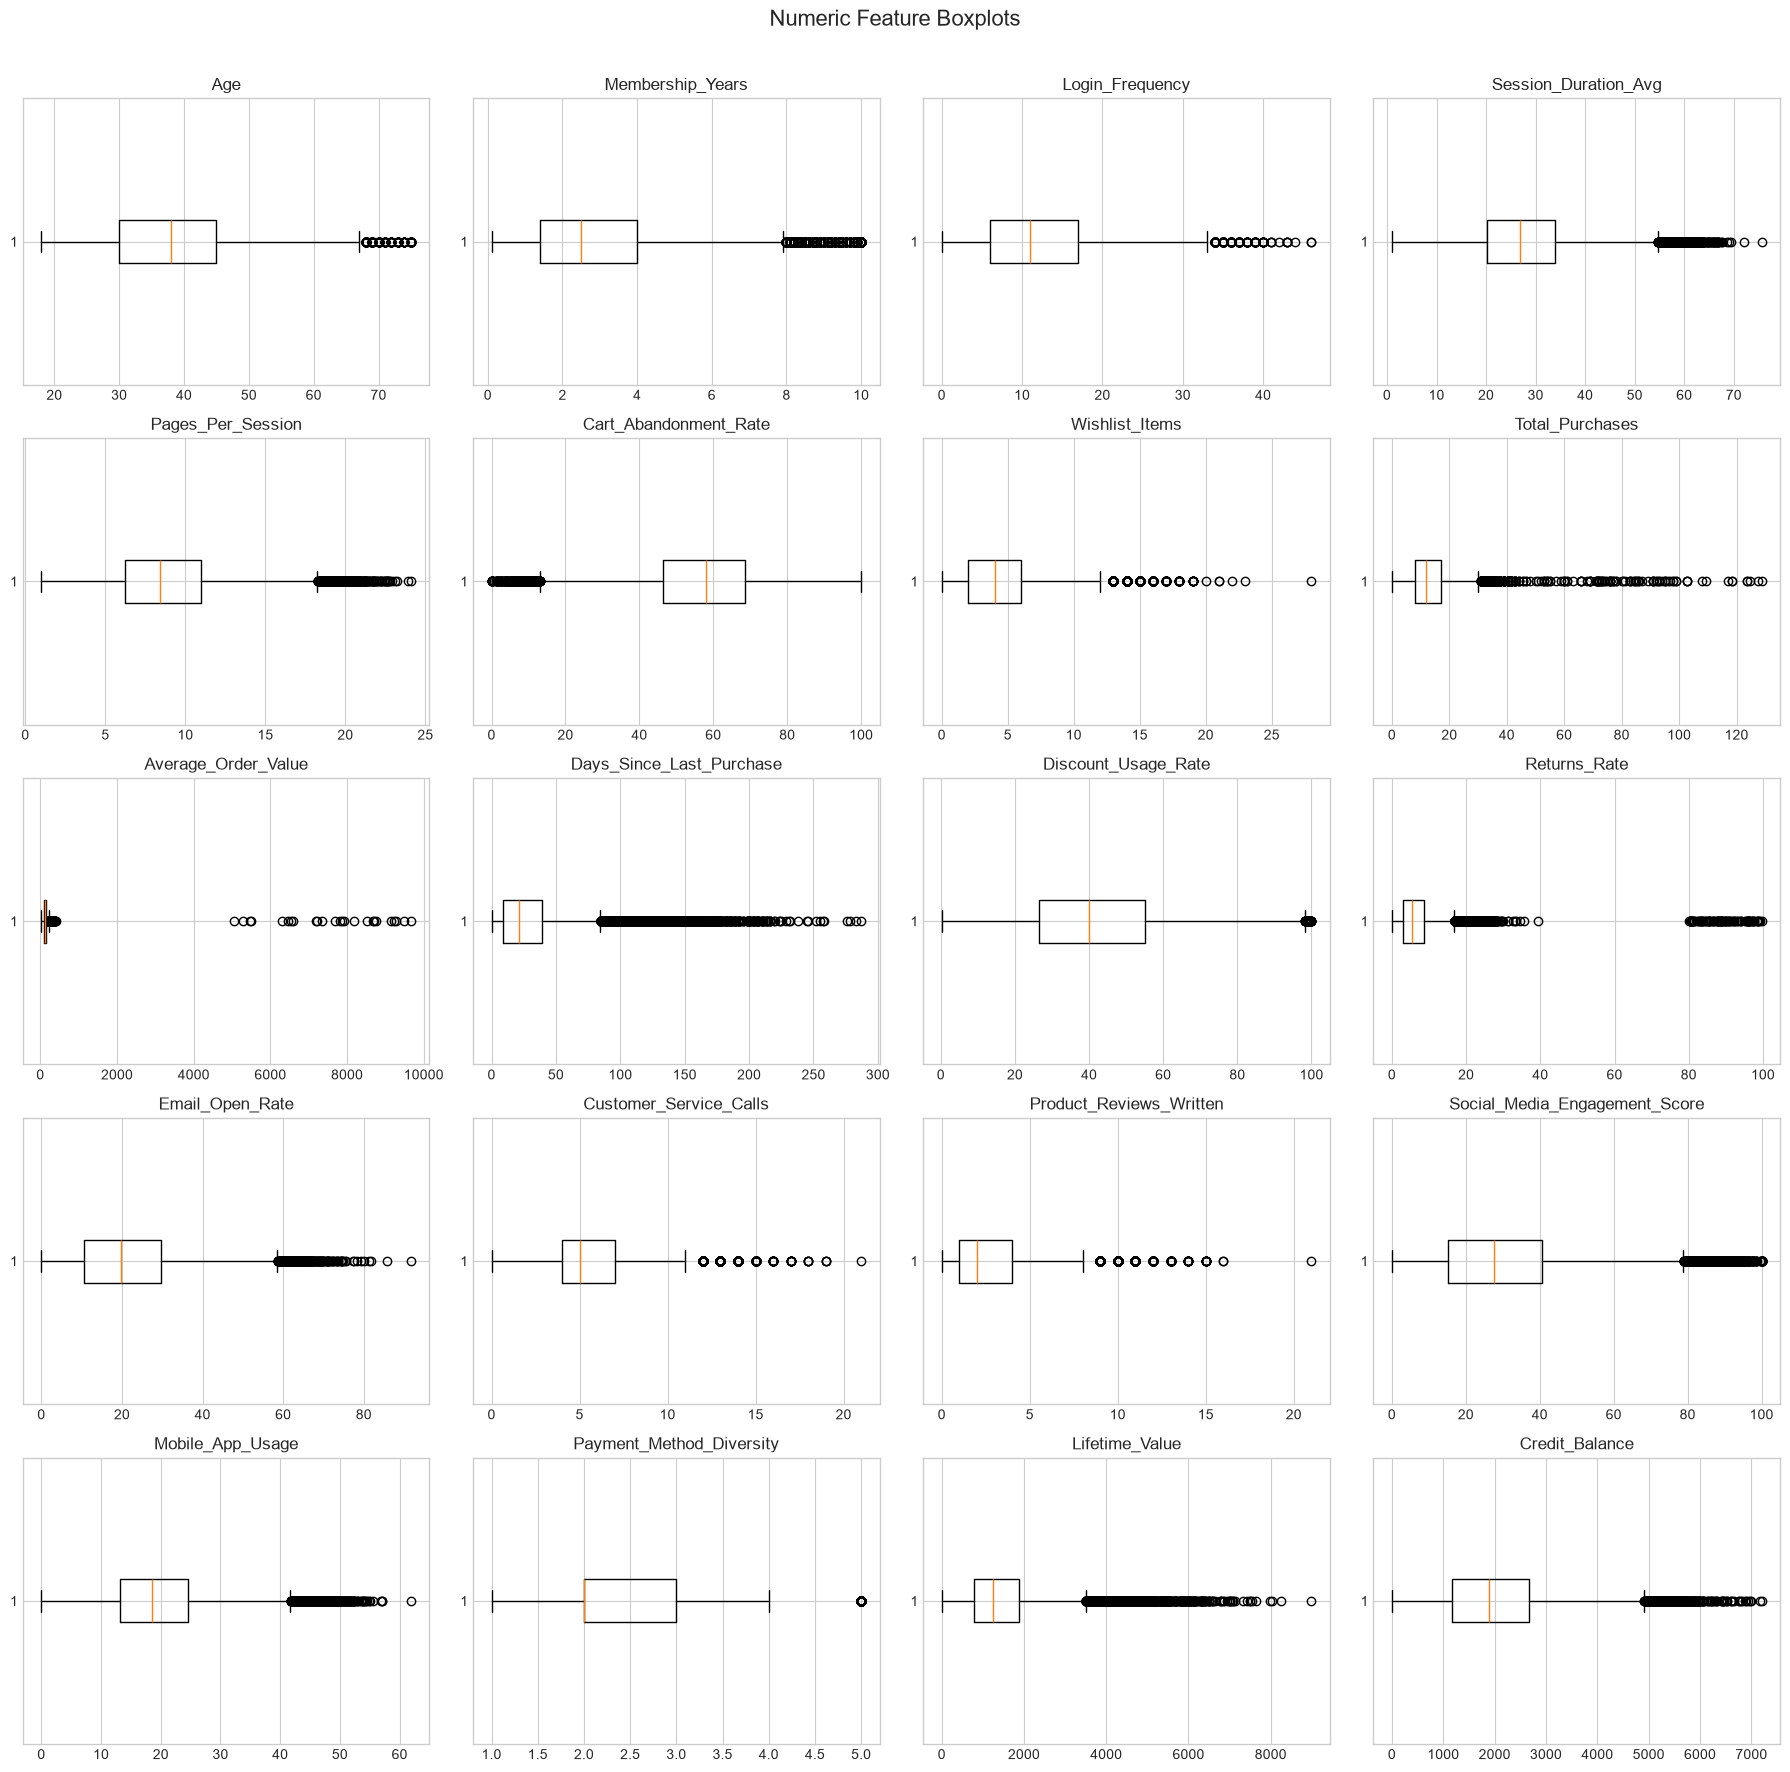

In [7]:
ncols = 4
nrows = int(np.ceil(len(plot_numeric_columns) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.5 * nrows))
axes = np.asarray(axes).ravel()

for axis, column in zip(axes, plot_numeric_columns):
    axis.boxplot(df[column].dropna(), vert=False)
    axis.set_title(column)

for axis in axes[len(plot_numeric_columns):]:
    axis.set_visible(False)

fig.suptitle("Numeric Feature Boxplots", fontsize=16, y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "numeric_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
outlier_rows = []
for column in numeric_columns:
    series = df[column].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((series < lower_bound) | (series > upper_bound)).sum()
    outlier_rows.append({
        "Feature": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percent": outlier_count / len(series) * 100,
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("Outlier_Count", ascending=False)
outlier_report.to_csv(OUTPUT_DIR / "numeric_outlier_report.csv", index=False, encoding="utf-8-sig")
outlier_report

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percent
9,Days_Since_Last_Purchase,-36.00,84.00,2726,5.46
17,Payment_Method_Diversity,0.50,4.50,2436,4.88
11,Returns_Rate,-5.15,16.85,1821,3.64
18,Lifetime_Value,-836.83,"3,500.59",1680,3.36
1,Membership_Years,-2.50,7.90,1575,3.15
13,Customer_Service_Calls,-0.50,11.50,1185,2.37
14,Product_Reviews_Written,-3.50,8.50,1088,2.18
8,Average_Order_Value,0.96,230.53,1002,2.01
6,Wishlist_Items,-4.00,12.00,857,1.72
16,Mobile_App_Usage,-3.90,41.70,691,1.38


Outlier theo IQR chỉ là dấu hiệu thống kê. Không tự động xóa dữ liệu nếu chưa có bằng chứng nghiệp vụ cho thấy giá trị đó sai.

## 4. Categorical Analysis

In [9]:
categorical_columns = ["Gender", "Country", "City", "Signup_Quarter"]
categorical_summary = pd.DataFrame({
    "Unique_Count": df[categorical_columns].nunique(),
    "Missing_Count": df[categorical_columns].isna().sum(),
    "Most_Frequent": df[categorical_columns].mode().iloc[0],
})
categorical_summary.to_csv(OUTPUT_DIR / "categorical_summary.csv", encoding="utf-8-sig")
categorical_summary

,Unique_Count,Missing_Count,Most_Frequent
Gender,3,0,Female
Country,8,0,USA
City,40,0,Houston
Signup_Quarter,4,0,Q3


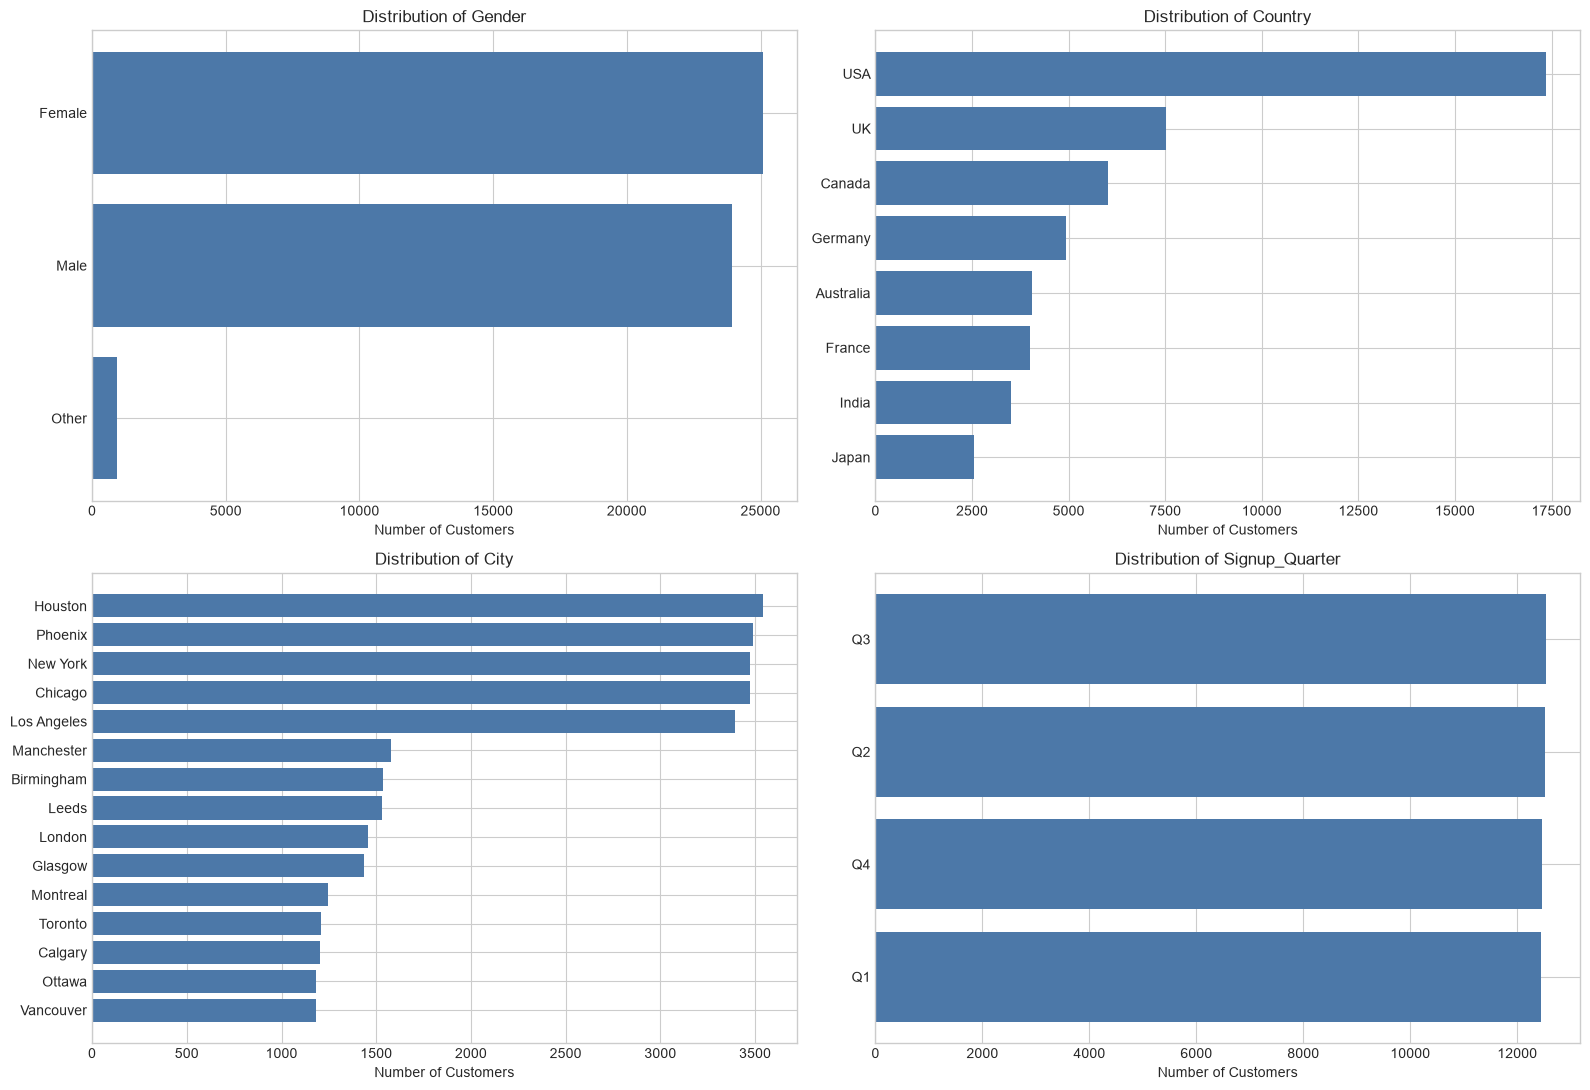

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for axis, column in zip(axes.ravel(), categorical_columns):
    counts = df[column].value_counts().head(15).sort_values()
    axis.barh(counts.index.astype(str), counts.values, color="#4C78A8")
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel("Number of Customers")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "categorical_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Analysis by Purchase Level

So sánh giá trị trung bình của các biến số, tỷ lệ churn và cơ cấu target trong từng biến phân loại.

In [11]:
behavior_columns = [
    "Login_Frequency", "Session_Duration_Avg", "Pages_Per_Session",
    "Wishlist_Items", "Average_Order_Value", "Days_Since_Last_Purchase",
    "Cart_Abandonment_Rate", "Discount_Usage_Rate", "Lifetime_Value",
]
behavior_summary = (
    df.groupby("Purchase_Level", observed=False)[behavior_columns]
    .mean()
    .reindex(level_order)
)
behavior_summary.to_csv(OUTPUT_DIR / "purchase_level_behavior_summary.csv", encoding="utf-8-sig")
behavior_summary

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Wishlist_Items,Average_Order_Value,Days_Since_Last_Purchase,Cart_Abandonment_Rate,Discount_Usage_Rate,Lifetime_Value
Purchase_Level,,,,,,,,,
Low,6.53,20.23,6.23,2.44,121.85,29.08,67.49,40.81,811.77
Medium,11.51,27.28,8.69,4.25,123.87,28.77,57.23,41.60,"1,445.32"
High,17.81,36.71,11.71,6.49,123.88,29.96,44.41,42.54,"2,186.17"


In [12]:
churn_by_level = (
    df.groupby("Purchase_Level", observed=False)["Churned"]
    .agg(["count", "mean"])
    .reindex(level_order)
)
churn_by_level["Churn_Rate_Percent"] = churn_by_level["mean"] * 100
churn_by_level.drop(columns="mean")

,count,Churn_Rate_Percent
Purchase_Level,,
Low,18953,38.63
Medium,15130,22.57
High,15877,23.35


In [13]:
categorical_target_tables = {}
for column in categorical_columns:
    table = pd.crosstab(df[column], df["Purchase_Level"], normalize="index").reindex(columns=level_order) * 100
    categorical_target_tables[column] = table
    print(f"\n{column} — Purchase Level (%)")
    display(table.round(2))


Gender — Purchase Level (%)


Purchase_Level,Low,Medium,High
Gender,,,
Female,37.93,30.27,31.80
Male,38.03,30.31,31.67
Other,35.90,30.02,34.08



Country — Purchase Level (%)


Purchase_Level,Low,Medium,High
Country,,,
Australia,37.90,31.03,31.07
Canada,37.96,30.88,31.16
France,37.46,29.82,32.72
Germany,37.69,30.01,32.30
India,37.39,29.64,32.97
Japan,36.59,32.00,31.41
UK,38.00,30.06,31.93
USA,38.40,30.07,31.54



City — Purchase Level (%)


Purchase_Level,Low,Medium,High
City,,,
Adelaide,37.38,31.86,30.76
Bangalore,36.68,27.65,35.67
Berlin,38.24,30.24,31.52
Birmingham,37.72,30.16,32.12
Brisbane,38.41,30.35,31.23
Calgary,38.77,28.79,32.45
Chennai,38.15,28.47,33.38
Chicago,38.21,29.48,32.31
Cologne,35.72,30.88,33.40



Signup_Quarter — Purchase Level (%)


Purchase_Level,Low,Medium,High
Signup_Quarter,,,
Q1,43.04,30.88,26.08
Q2,43.46,30.95,25.60
Q3,42.78,31.05,26.18
Q4,22.41,28.26,49.33


**Nhận xét từ dữ liệu hiện tại:** Tần suất đăng nhập, thời lượng phiên, số trang mỗi phiên, số sản phẩm yêu thích và lifetime value tăng dần từ `Low` đến `High`. Tỷ lệ bỏ giỏ giảm dần. Churn của nhóm `Low` cao hơn rõ rệt, trong khi average order value và số ngày kể từ lần mua gần nhất không khác biệt lớn giữa ba nhóm.

## 6. Correlation Analysis

Ma trận tương quan Pearson chỉ áp dụng cho các biến số và phản ánh quan hệ tuyến tính. `Purchase_Level` được mã hóa thứ tự tạm thời (`Low=0`, `Medium=1`, `High=2`) để phục vụ sàng lọc, không phải để chứng minh quan hệ nhân quả.

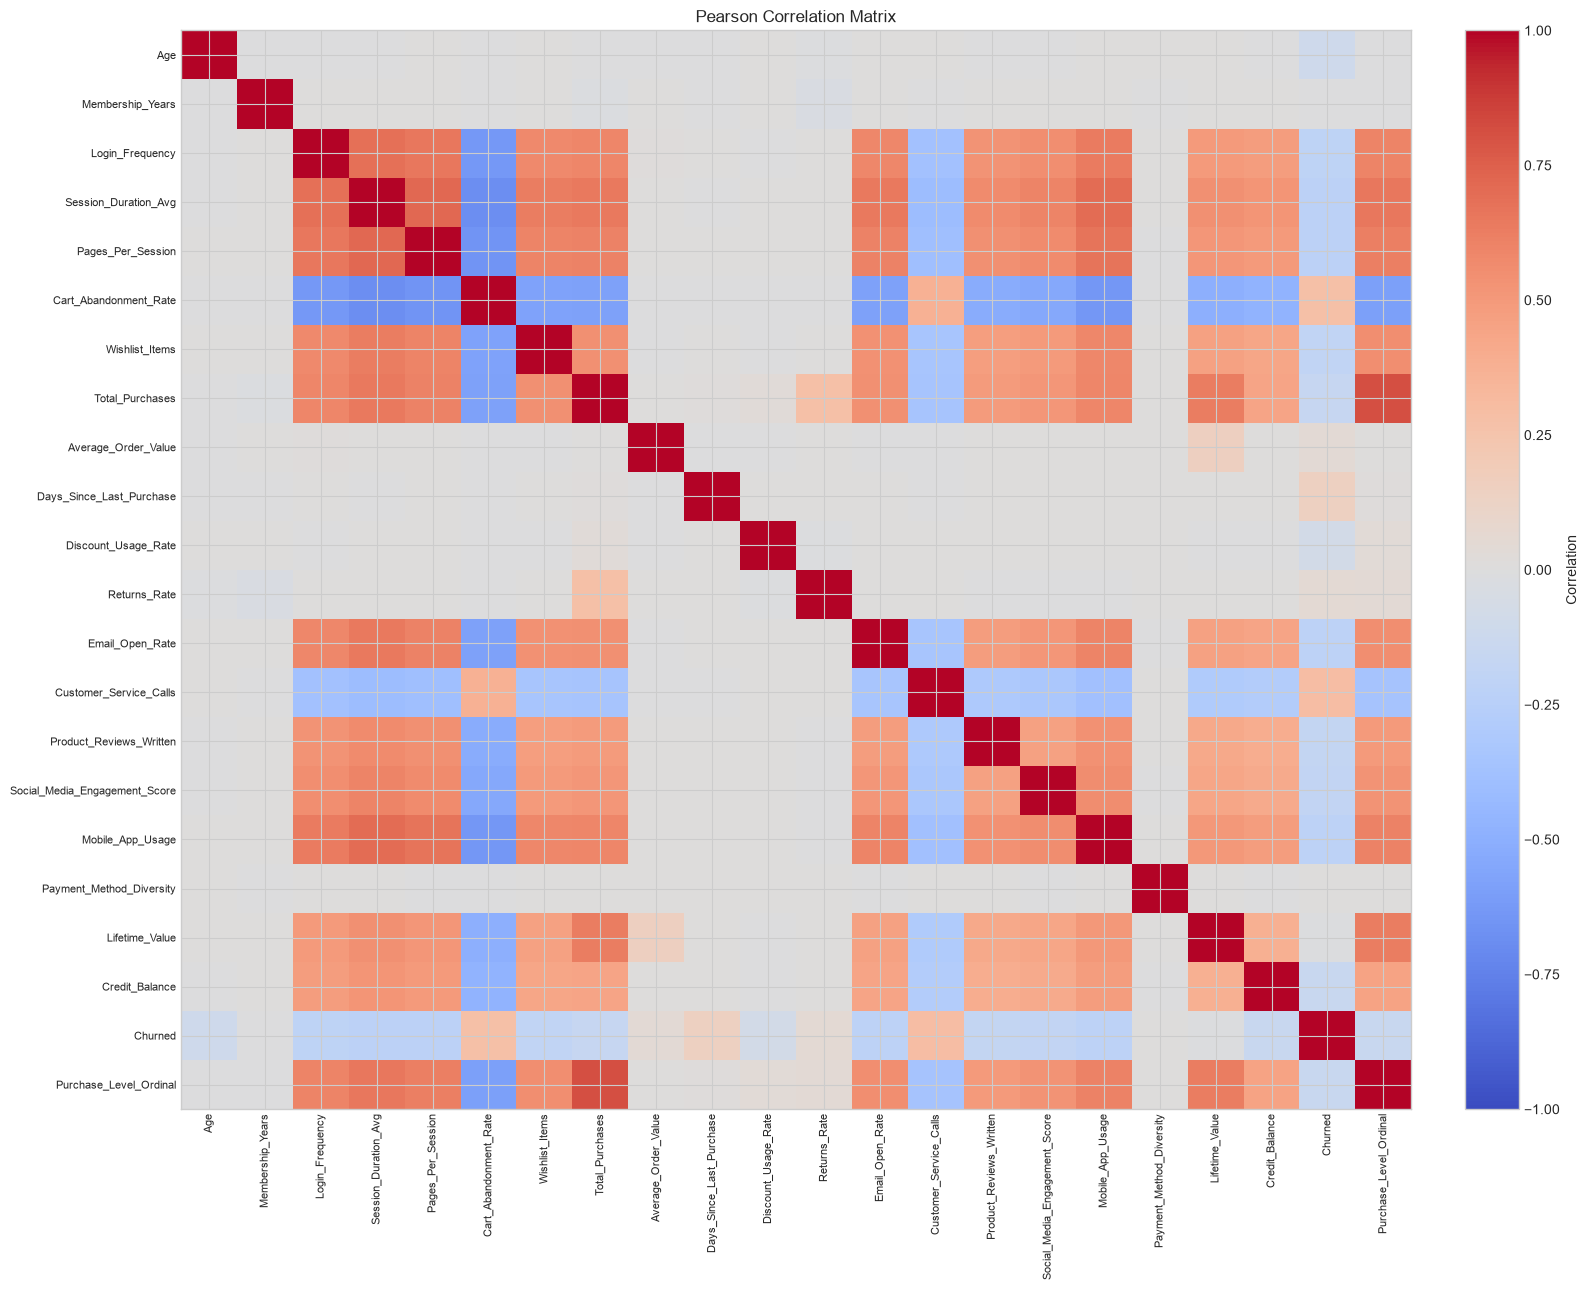

In [14]:
correlation_data = df[numeric_columns].copy()
correlation_data["Purchase_Level_Ordinal"] = df["Purchase_Level"].map({"Low": 0, "Medium": 1, "High": 2}).astype(float)
correlation_matrix = correlation_data.corr()
correlation_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv", encoding="utf-8-sig")

fig, axis = plt.subplots(figsize=(16, 13))
image = axis.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axis.set_xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=90, fontsize=8)
axis.set_yticks(range(len(correlation_matrix.index)), correlation_matrix.index, fontsize=8)
axis.set_title("Pearson Correlation Matrix")
fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04, label="Correlation")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()

In [15]:
target_correlations = (
    correlation_matrix["Purchase_Level_Ordinal"]
    .drop("Purchase_Level_Ordinal")
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .to_frame("Correlation_With_Purchase_Level")
)
target_correlations

,Correlation_With_Purchase_Level
Total_Purchases,0.81
Session_Duration_Avg,0.65
Lifetime_Value,0.63
Pages_Per_Session,0.62
Mobile_App_Usage,0.60
Login_Frequency,0.60
Cart_Abandonment_Rate,-0.59
Email_Open_Rate,0.55
Wishlist_Items,0.55
Social_Media_Engagement_Score,0.52


## 7. Data Leakage Audit

`Total_Purchases` là biến tạo ra target nên bắt buộc phải loại khỏi feature đầu vào. Các biến có tương quan mạnh chỉ được đánh dấu để rà soát nguồn gốc; tương quan cao không tự động đồng nghĩa với leakage.

In [16]:
target_ordinal = df["Purchase_Level"].map({"Low": 0, "Medium": 1, "High": 2}).astype(float)
audit_rows = []
for column in numeric_columns:
    if column == "Total_Purchases":
        decision = "EXCLUDE — direct target leakage"
    elif column in {"Lifetime_Value", "Average_Order_Value"}:
        decision = "REVIEW — verify business definition and availability at prediction time"
    else:
        decision = "KEEP candidate — validate in preprocessing/modeling"

    audit_rows.append({
        "Feature": column,
        "Correlation_With_Total_Purchases": df[column].corr(df["Total_Purchases"]),
        "Correlation_With_Target_Ordinal": df[column].corr(target_ordinal),
        "Initial_Decision": decision,
    })

leakage_audit = pd.DataFrame(audit_rows)
leakage_audit["Absolute_Target_Correlation"] = leakage_audit["Correlation_With_Target_Ordinal"].abs()
leakage_audit = leakage_audit.sort_values("Absolute_Target_Correlation", ascending=False)
leakage_audit.to_csv(OUTPUT_DIR / "data_leakage_audit.csv", index=False, encoding="utf-8-sig")
leakage_audit

,Feature,Correlation_With_Total_Purchases,Correlation_With_Target_Ordinal,Initial_Decision,Absolute_Target_Correlation
7,Total_Purchases,1.00,0.81,EXCLUDE — direct target leakage,0.81
3,Session_Duration_Avg,0.64,0.65,KEEP candidate — validate in preprocessing/mod...,0.65
18,Lifetime_Value,0.63,0.63,REVIEW — verify business definition and availa...,0.63
4,Pages_Per_Session,0.61,0.62,KEEP candidate — validate in preprocessing/mod...,0.62
16,Mobile_App_Usage,0.59,0.60,KEEP candidate — validate in preprocessing/mod...,0.60
2,Login_Frequency,0.59,0.60,KEEP candidate — validate in preprocessing/mod...,0.60
5,Cart_Abandonment_Rate,-0.58,-0.59,KEEP candidate — validate in preprocessing/mod...,0.59
12,Email_Open_Rate,0.54,0.55,KEEP candidate — validate in preprocessing/mod...,0.55
6,Wishlist_Items,0.54,0.55,KEEP candidate — validate in preprocessing/mod...,0.55
15,Social_Media_Engagement_Score,0.51,0.52,KEEP candidate — validate in preprocessing/mod...,0.52


### Quy tắc dùng cho bước classification

- Loại `Total_Purchases` khỏi `X` trong mọi mô hình.
- Chỉ sử dụng biến có thể biết tại thời điểm dự đoán.
- Rà soát định nghĩa nghiệp vụ của `Lifetime_Value`; nên thử nghiệm cả hai kịch bản có và không có biến này.
- `Average_Order_Value` không tự động bị loại, nhưng phải xác nhận cách tính và thời điểm quan sát.
- Mọi bước preprocessing phải được fit chỉ trên training set để tránh leakage từ train/test split.

## 8. EDA Conclusions

1. Target có phân bố tương đối cân bằng: `Low 37.94%`, `Medium 30.28%`, `High 31.78%`; chưa cần SMOTE ở giai đoạn hiện tại.
2. Mức độ tương tác tăng rõ từ `Low` đến `High`, đặc biệt ở login frequency, session duration, pages per session và wishlist items.
3. Cart abandonment giảm khi mức mua tăng; churn của nhóm `Low` cao hơn hai nhóm còn lại.
4. Average order value và days since last purchase không thể hiện khác biệt lớn giữa ba nhóm trong thống kê trung bình.
5. Outlier được ghi nhận nhưng không tự động loại bỏ nếu chưa có căn cứ nghiệp vụ.
6. `Total_Purchases` là leakage trực tiếp và phải bị loại khỏi đầu vào mô hình. `Lifetime_Value` cần được đánh giá bằng thí nghiệm ablation trong notebook classification.
7. Bước tiếp theo là `03_classification.ipynb`: split dữ liệu có stratify, xây preprocessing pipeline và thiết lập Logistic Regression làm baseline trước khi so sánh các mô hình phức tạp hơn.